# Tails, trails, and a supernova in Rubin eDP2 shallow coadds

This notebook reproduces, from scratch, one example of each science case in the Letter
*Tails and Trails: Comets and NEOs Survive Co-addition in Rubin Early Data Preview 2*
(Chandler et al., [arXiv:2609.30361](https://arxiv.org/abs/2609.30361)). It runs end to end
on the [Rubin Science Platform](https://data.lsst.cloud) Notebook Aspect with the
**LSST** kernel.

| Target | Science case | Source catalog | Letter epoch (TAI date, band) |
| --- | --- | --- | --- |
| C/2024 G6 (ATLAS) | cometary activity | MPC comet elements (`allcometels`) | 2025-07-20, *g* |
| 2025 NC₆ | activity on an asteroid-designated object (our discovery) | MPCORB | 2025-07-20, *g* |
| 2025 OP₁ | trailed near-Earth object (118 px predicted trail) | MPCORB | 2025-07-23, *g* |
| SN 2025nbh | Type II supernova beside AGC 114905 | TNS position | 2025-07-22, *r* |

**Idea.** Early Data Preview 2 (eDP2) releases deep coadds, not single-visit images. Where
only one or two visits contributed to a coadd cell (*n1*/*n2*), the coadd *is*
effectively a single-epoch image. So we (1) predict where known Solar System bodies fall in
eDP2 visits with **Ponder** (which runs the **Sorcha** survey simulator), (2) read each
coadd's cell provenance with the Butler to keep only predictions whose own visit is the
one or two contributors within 5″, and (3) cut out the image. The supernova uses the
same provenance test at a fixed sky position.

**What gets installed.** Ponder and Sorcha go into their own virtual environment under
`~/edp2_demo/`, so the LSST kernel is left untouched (Sorcha pins its own `numba`,
`assist`, and `rebound`). Nothing else is installed. You **do not** need the
`Rubin-eDP2-SolSys-Explorer` repository: the few pieces of its method that we use are
re-implemented below in a few lines each and marked *"repo:"* with the module they
mirror, so results can be traced to the code used for the Letter.

**Cost of a first run:** about 2.5 GB in your home directory (Ponder environment ≈1 GB,
Sorcha ephemeris files ≈0.8 GB, MPC catalogs ≈0.2 GB, DP2 pointing database 0.12 GB), and
roughly 15–30 minutes, most of it installing and downloading. Re-runs reuse everything.
Run the cells in order; each step is safe to re-run.

In [1]:
from pathlib import Path

# Letter epochs. Ponder must reproduce each of these visits; the notebook stops if not.
SSO_TARGETS = {
    "C/2024 G6 (ATLAS)": dict(catalog="comet", visit=2025071900309, detector=127, band="g"),
    "2025 NC6": dict(catalog="mpcorb", visit=2025071900502, detector=152, band="g"),
    "2025 OP1": dict(catalog="mpcorb", visit=2025072200183, detector=153, band="g"),
}
# TNS position and discovery date; the Letter shows the n1 r-band coadd (UTC 2025-07-22).
SUPERNOVA = dict(
    name="SN 2025nbh",
    ra=21.326238,
    dec=7.357503,
    discovered="2025-06-07",
    band="r",
    host_note='AGC 114905, ~12.7" NE',
)

WORK = Path.home() / "edp2_demo"
RERUN_PONDER = False  # True discards earlier Ponder results and simulates again

# Pinned software and inputs.
PONDER = (
    "git+https://github.com/lincc-frameworks/ponder.git@ec4d601ce02f15209104abb46a092c56dce83a66"
)
SORCHA, ASSIST, REBOUND = "sorcha==1.2.1", "assist==1.2.3", "rebound>=4.4.11,<5"
POINTING_DB_URL = "https://s3df.slac.stanford.edu/data/rubin/sim-data/prelsst/dp2_visits.db"
POINTING_DB_SHA256 = "3ff666cbfe4052db82b864cafdd85332fb55b47e7d7f80e5276866811e3afba6"
MPC_URLS = {
    "comet": "https://www.minorplanetcenter.net/Extended_Files/allcometels.json.gz",
    "mpcorb": "https://www.minorplanetcenter.net/Extended_Files/mpcorb_extended.json.gz",
}

# eDP2 Butler and image geometry.
BUTLER_REPO, COLLECTION, SKYMAP = "dp2", "dp2", "lsst_cells_v2"
PROVENANCE_RADIUS_ARCSEC = 5.0  # n = distinct visits in coadd cells within this radius
PIXEL_SCALE_ARCSEC = 0.2
CUTOUT_PIXELS = 600  # 120" x 120", as in the Letter's figures

for sub in ("inputs", "ponder", "products"):
    (WORK / sub).mkdir(parents=True, exist_ok=True)
print("working directory:", WORK)

working directory: /home/orion/edp2_demo


## 1. Install Ponder and Sorcha

[Ponder](https://github.com/lincc-frameworks/ponder) orchestrates
[Sorcha](https://github.com/dirac-institute/sorcha) runs against a pointing database.
Both go into a private virtual environment, called only through their command-line tools.

* **REBOUND before ASSIST, without build isolation.** ASSIST ships only as source and
  is compiled against whatever REBOUND it finds. Installing REBOUND first and building
  ASSIST with `--no-build-isolation` makes it link against that exact REBOUND, which
  avoids the ASSIST/REBOUND binary mismatch we hit with isolated builds. (REBOUND 4.x has
  no Python 3.13 wheel, so on a 3.13 kernel it compiles too; the LSST stack provides
  the compiler.)
* **Clean environment.** The LSST kernel sets `PYTHONPATH` to the Science Pipelines;
  we drop it for every call into the private environment so the two never mix. We also
  drop the stack's empty `CONDA_BUILD_CROSS_COMPILATION`, which otherwise makes ASSIST's
  build look for a conda-forge cross-compile prefix and fail, and the kernel's
  `MPLBACKEND`, an inline backend that Sorcha's matplotlib cannot load.
* `sorcha bootstrap` downloads the ephemeris files ASSIST needs (≈0.8 GB, once) into
  Sorcha's default cache.

Anyone publishing with Ponder must follow
[Sorcha's citation requirements](https://github.com/dirac-institute/sorcha);
`sorcha cite` prints them.

In [2]:
import os
import subprocess
import sys

VENV = WORK / "ponder-venv"
VENV_BIN = VENV / "bin"
# Also drop the stack's empty CONDA_BUILD_CROSS_COMPILATION (ASSIST's build mistakes it for a
# conda-forge cross-compile) and the kernel's inline MPLBACKEND (unknown outside Jupyter).
DROP = ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "CONDA_BUILD_CROSS_COMPILATION", "MPLBACKEND")
CLEAN_ENV = {k: v for k, v in os.environ.items() if k not in DROP}
PONDER_ENV = {**CLEAN_ENV, "PATH": f"{VENV_BIN}{os.pathsep}{CLEAN_ENV['PATH']}"}


def run(command, **kwargs):
    """Run a command, echo it, and stop the notebook if it fails."""
    command = [str(part) for part in command]
    print("$", " ".join(command), flush=True)
    subprocess.run(command, check=True, **kwargs)


if not (VENV_BIN / "ponder").exists():
    pip = [VENV_BIN / "python", "-m", "pip", "install", "--quiet"]
    run([sys.executable, "-m", "venv", "--clear", VENV], env=CLEAN_ENV)
    run([*pip, "--upgrade", "pip", "setuptools", "wheel", "numpy"], env=PONDER_ENV)
    run([*pip, REBOUND], env=PONDER_ENV)
    run([*pip, "--no-build-isolation", ASSIST], env=PONDER_ENV)
    run([*pip, SORCHA, f"ponder @ {PONDER}"], env=PONDER_ENV)
run(
    [
        VENV_BIN / "python",
        "-c",
        "import assist, rebound, sorcha, ponder, sys; "
        "print('python', sys.version.split()[0], '| sorcha', sorcha.__version__, "
        "'| rebound', rebound.__version__, '| ponder', ponder.__version__)",
    ],
    env=PONDER_ENV,
)
run([VENV_BIN / "sorcha", "bootstrap"], env=PONDER_ENV)

$ /home/orion/edp2_demo/ponder-venv/bin/python -c import assist, rebound, sorcha, ponder, sys; print('python', sys.version.split()[0], '| sorcha', sorcha.__version__, '| rebound', rebound.__version__, '| ponder', ponder.__version__)


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


python 3.13.9 | sorcha 1.2.1 | rebound 4.6.0 | ponder 0.1.dev42+gec4d601ce


$ /home/orion/edp2_demo/ponder-venv/bin/sorcha bootstrap


        Use pytest instead. [astropy.tests.runner]
        Use pytest instead. [astropy.utils.decorators]


Checking cache for existing files.
All expected files were found in the local cache: /home/orion/.cache/sorcha/


## 2. Inputs: pointing database, orbits, and Sorcha configuration

* **Pointing database.** The official DP2 visit database published by Rubin
  ([survey-strategy page](https://survey-strategy.lsst.io/progress/prelsst/prelsst_dp2.html));
  the download is checked against Rubin's SHA-256.
* **Orbits.** Today's MPC extended catalogs, reduced to our three objects. These are
  *newer* orbits than the August 2026 snapshots used in the Letter, so predicted positions
  can differ slightly; the visits should not. The 183 MB MPCORB file is streamed one object
  at a time (≈1.6 million objects, under a minute) instead of being loaded whole.
* **No orbit-quality filter.** By default Ponder drops MPCORB orbits with uncertainty
  `U > 6` and arcs shorter than 3 days. 2025 OP₁ has `U = 7` and a one-day arc (it was
  observed only around these eDP2 epochs), so we pass `--no-filter-orbits`: we chose the
  objects ourselves.
* **Sorcha configuration** — *repo:* `configs/sorcha_dp2_comets_mag26.ini` and
  `configs/sorcha_dp2_neos_mag26.ini`, reproduced verbatim apart from comments and two
  lines. The public Ponder release writes only `H_r` and a `g−r` colour, while Sorcha needs
  a colour per simulated band and a slope `G` for the HG law, so this demo simulates *g* and
  *r* only (`observing_filters = r,g`) with no phase function for asteroids either; the
  Letter's runs used all six bands and the HG law (*G* = 0.15). Only geometry (full LSSTCam
  footprint) and a faint limit of *m* = 26 are applied, so this changes no positions.

In [3]:
import gzip
import hashlib
import json
import urllib.request


def download(url, path):
    """Fetch once; a partial file never takes the final name."""
    if not path.exists():
        print("downloading", url, flush=True)
        partial = path.with_name(path.name + ".part")
        urllib.request.urlretrieve(url, partial)
        partial.rename(path)
    return path


def stream_json_array(path, chunk=1 << 20):
    """Yield each object of a (gzipped) top-level JSON array without loading the file."""
    decoder, buffer = json.JSONDecoder(), ""
    with gzip.open(path, "rt", encoding="utf-8") as handle:
        while True:
            text = handle.read(chunk)
            buffer += text
            position = 0
            while True:
                while position < len(buffer) and buffer[position] in " \t\r\n,[]":
                    position += 1
                try:
                    item, position = decoder.raw_decode(buffer, position)
                except json.JSONDecodeError:
                    break  # object continues in the next chunk
                yield item
            buffer = buffer[position:]
            if not text:
                if buffer.strip():
                    raise ValueError(f"unparsed data at the end of {path}")
                return


# Pointing database, verified against Rubin's published checksum.
POINTING_DB = download(POINTING_DB_URL, WORK / "inputs" / "dp2_visits.db")
digest = hashlib.sha256(POINTING_DB.read_bytes()).hexdigest()
assert digest == POINTING_DB_SHA256, f"pointing database checksum mismatch: {digest}"

# Orbits: keep only our targets. Comets are keyed by full name, MPCORB rows by designation.
ORBITS = {}
for catalog, url in MPC_URLS.items():
    wanted = {name for name, t in SSO_TARGETS.items() if t["catalog"] == catalog}
    key = "Designation_and_name" if catalog == "comet" else "Principal_desig"
    rows = [
        row
        for row in stream_json_array(download(url, WORK / "inputs" / Path(url).name))
        if row.get(key) in wanted
    ]
    missing = wanted - {row[key] for row in rows}
    assert not missing, f"not found in the MPC {catalog} catalog: {missing}"
    ORBITS[catalog] = WORK / "inputs" / f"{catalog}_targets.json"
    ORBITS[catalog].write_text(json.dumps(rows, indent=1))
    for row in rows:
        print(
            f"{row[key]:20s} q = {row.get('Perihelion_dist', 0):.3f} au  e = {row['e']:.4f}  "
            f"U = {row.get('U', '-')}  {catalog} orbit"
        )

SORCHA_CONFIG = """
[INPUT]
ephemerides_type = ar
eph_format = csv
size_serial_chunk = 5000
aux_format = csv
pointing_sql_query = SELECT observationId, observationStartMJD as observationStartMJD_TAI, visitTime, visitExposureTime, band as optFilter, seeingFwhmGeom as seeingFwhmGeom_arcsec, seeingFwhmEff as seeingFwhmEff_arcsec, fiveSigmaDepth as fieldFiveSigmaDepth_mag, fieldRA as fieldRA_deg, fieldDec as fieldDec_deg, rotSkyPos as fieldRotSkyPos_deg FROM observations WHERE band IS NOT NULL AND fieldRA IS NOT NULL AND fieldDec IS NOT NULL AND seeingFwhmGeom IS NOT NULL AND seeingFwhmEff IS NOT NULL AND fiveSigmaDepth IS NOT NULL ORDER BY observationId

[SIMULATION]
ar_ang_fov = 2.06
ar_fov_buffer = 0.20
ar_picket = 1
ar_obs_code = X05
ar_healpix_order = 6

[FILTERS]
observing_filters = r,g

[SATURATION]

[PHASECURVES]
phase_function = {phase}

[FOV]
camera_model = footprint
footprint_edge_threshold = 2.0

[FADINGFUNCTION]

[LINKINGFILTER]

[OUTPUT]
output_format = csv
output_columns = all

[LIGHTCURVE]
lc_model = none

[ACTIVITY]
comet_activity = none

[EXPERT]
mag_limit = 26
default_snr_cut = False
randomization_on = False
vignetting_on = False
trailing_losses_on = False
brute_force = True
"""  # noqa: E501
CONFIGS = {}
for catalog, phase in (("comet", "none"), ("mpcorb", "none")):
    CONFIGS[catalog] = WORK / "inputs" / f"sorcha_dp2_{catalog}_mag26.ini"
    CONFIGS[catalog].write_text(SORCHA_CONFIG.format(phase=phase).lstrip())

C/2024 G6 (ATLAS)    q = 6.430 au  e = 1.0014  U = -  comet orbit


2025 NC6             q = 2.155 au  e = 0.4915  U = 0  mpcorb orbit
2025 OP1             q = 1.012 au  e = 0.5303  U = 7  mpcorb orbit


## 3. Predict eDP2 detections with Ponder

One Ponder run per catalog type (`--comet` switches to cometary elements). Each run
simulates the targets against the 9,022 *g* and *r* DP2 visits (of 28,698; see step 2)
and writes a parquet table of predicted detections: one row per visit and detector in
which the object falls.

The predicted trail length uses each visit's actual exposure time from the pointing
database, `rate × t_exp / 0.2″` (*repo:* `trailing_metrics.py`, which assumed 30 s, or
38 s in *u*; C/2024 G6's *g* visit was in fact 38 s).

In [4]:
import sqlite3

import numpy as np
import pandas as pd
from astropy.time import Time

with sqlite3.connect(POINTING_DB) as db:
    VISITS = pd.read_sql(
        "SELECT observationId AS visit, band, observationStartMJD AS start_mjd_tai, "
        "visitExposureTime AS exptime_s FROM observations",
        db,
    ).set_index("visit")
VISITS["mid_utc"] = Time(
    VISITS.start_mjd_tai + VISITS.exptime_s / 2 / 86400, format="mjd", scale="tai"
).utc.iso


def ponder_detections(catalog):
    """Run Ponder once per catalog type and return its newest detection table."""
    workdir = WORK / "ponder" / catalog
    if RERUN_PONDER and workdir.exists():
        import shutil

        shutil.rmtree(workdir)
    workdir.mkdir(parents=True, exist_ok=True)

    def results():
        return sorted(
            p for p in (workdir / "results").glob("*_job_*.parquet") if not p.stem.endswith("_ew")
        )

    if not results():
        run(
            [
                VENV_BIN / "ponder",
                "--db",
                POINTING_DB,
                "--orbits",
                ORBITS[catalog],
                "--config",
                CONFIGS[catalog],
                "--no-filter-orbits",
                "--sorcha-workers",
                "1",
                *(["--comet"] if catalog == "comet" else []),
            ],
            cwd=workdir,
            env=PONDER_ENV,
        )
    return pd.read_parquet(results()[-1])


detections = pd.concat([ponder_detections("comet"), ponder_detections("mpcorb")], ignore_index=True)
detections = detections[detections.ObjID.isin(SSO_TARGETS)].copy()
detections["visit"] = detections.FieldID.astype("int64")
detections["detector"] = detections.detectorID.astype("int64")
detections["band"] = detections.optFilter.str.strip()
detections["utc"] = Time(detections.fieldMJD_TAI.to_numpy(), format="mjd", scale="tai").utc.iso
rate_arcsec_s = np.hypot(detections.RARateCosDec_deg_day, detections.DecRate_deg_day) * 3600 / 86400
detections["trail_px"] = (
    rate_arcsec_s * VISITS.exptime_s.reindex(detections.visit).to_numpy() / PIXEL_SCALE_ARCSEC
)

summary = detections.groupby("ObjID").agg(
    predicted=("visit", "size"),
    first=("utc", "min"),
    last=("utc", "max"),
    max_trail_px=("trail_px", "max"),
)
summary

,predicted,first,last,max_trail_px
ObjID,,,,
2025 NC6,21,2025-07-02 06:52:37.158,2025-11-22 02:04:41.828,1.166430
2025 OP1,6,2025-07-23 02:38:33.880,2025-08-27 09:21:46.001,118.282492
C/2024 G6 (ATLAS),11,2025-06-23 03:33:48.406,2025-07-20 03:10:55.419,1.721774


## 4. Which predictions land in single-visit coadd cells?

eDP2 deep coadds are *cell-based*: every patch is a grid of cells, and each cell records
exactly which visits contributed (the `provenance` component). For a position we sample a
5″-radius disc on a 0.1″ grid, find every cell it touches, and collect their contributing
visits. A prediction is kept when that set has **one or two** visits (*n1*/*n2*) and
includes the prediction's own visit. (*repo:* `component_recovery.visits_from_components`
and `provenance.center_source_visits`; the Letter read the same provenance through the
public image service, here we read it with the Butler.) Because the demo simulates *g*
and *r* only (step 2), the crosstab below covers *g*/*r* predictions only.

When a position lies in overlapping patches, the patch whose cell grid contains it
farthest from an edge is used. Cutouts are resampled from that single patch onto a
north-up, east-left 0.2″/pixel grid (*repo:* `cutouts.py`), so a cutout near a patch
edge can have blank (NaN) margins; the Letter's cutouts instead mosaic neighbouring
patches.

In [5]:
import functools
import math
from collections import defaultdict

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from lsst.daf.butler import Butler
from lsst.geom import SpherePoint, degrees
from scipy.ndimage import map_coordinates

butler = Butler(BUTLER_REPO, collections=COLLECTION)
skymap = butler.get(butler.query_datasets("skyMap", skymap=SKYMAP, find_first=True)[0])


@functools.cache
def coadd(tract, patch, band):
    """Projection, cell grid and per-cell visits of one deep_coadd patch (None if absent)."""
    refs = butler.query_datasets(
        "deep_coadd",
        skymap=SKYMAP,
        tract=tract,
        patch=patch,
        band=band,
        find_first=True,
        explain=False,
    )
    if not refs:
        return None
    ref = refs[0]
    cell_visits = defaultdict(set)
    for row in butler.get(ref.makeComponentRef("provenance")).contributions:
        cell_visits[(int(row["cell_i"]), int(row["cell_j"]))].add(int(row["visit"]))
    return dict(
        ref=ref,
        cell_visits=cell_visits,
        projection=butler.get(ref.makeComponentRef("sky_projection")),
        grid=butler.get(ref.makeComponentRef("psf")).bounds.grid,
    )


def aperture(ra, dec, radius=PROVENANCE_RADIUS_ARCSEC):
    """The exact position first, then a 0.1" grid filling the disc."""
    steps = np.linspace(-radius, radius, 2 * max(32, math.ceil(radius / 0.1)) + 1)
    dy, dx = np.meshgrid(steps, steps, indexing="ij")
    inside = dx**2 + dy**2 <= radius**2 + 1e-12
    center = SkyCoord(ra, dec, unit="deg")
    return SkyCoord(
        lon=np.r_[0, dx[inside]] * u.arcsec,
        lat=np.r_[0, dy[inside]] * u.arcsec,
        frame=center.skyoffset_frame(),
    ).transform_to(center.frame)


def provenance(ra, dec, band):
    """Visits contributing within 5" of (ra, dec) in the best-containing deep_coadd patch."""
    best, sky = None, aperture(ra, dec)
    for tract_info, patches in skymap.findTractPatchList([SpherePoint(ra, dec, degrees)]):
        for patch_info in patches:
            key = (tract_info.getId(), tract_info.getSequentialPatchIndex(patch_info), band)
            entry = coadd(*key)
            if entry is None:
                continue
            xy, box, shape = (
                entry["projection"].sky_to_pixel(sky),
                entry["grid"].bbox,
                entry["grid"].cell_shape,
            )
            x, y = np.asarray(xy.x, float), np.asarray(xy.y, float)
            ok = (
                np.isfinite(x)
                & np.isfinite(y)
                & (x >= box.x.start)
                & (x < box.x.stop)
                & (y >= box.y.start)
                & (y < box.y.stop)
            )
            if not ok[0]:
                continue  # the exact position is outside this patch's cell grid
            edge = min(x[0] - box.x.start, box.x.stop - x[0], y[0] - box.y.start, box.y.stop - y[0])
            cells = {
                (math.floor((b - box.y.start) / shape.y), math.floor((a - box.x.start) / shape.x))
                for a, b in zip(x[ok], y[ok], strict=True)
            }
            visits = sorted(set().union(*(entry["cell_visits"].get(c, set()) for c in cells)))
            if best is None or edge > best["edge"]:
                best = dict(key=key, visits=visits, n=len(visits), edge=edge)
    return best


@functools.lru_cache(maxsize=6)
def coadd_image(key):
    """Full patch image in nJy with an array-indexed FITS WCS."""
    entry = coadd(*key)
    image = butler.get(entry["ref"].makeComponentRef("image"))
    wcs = entry["projection"].as_fits_wcs(image.bbox)
    return np.asarray(image.array, dtype=np.float32) * image.unit.to(u.nJy), wcs


def north_up_cutout(key, ra, dec, size=CUTOUT_PIXELS):
    """Bilinear resampling onto a north-up, east-left 0.2"/px grid centred on (ra, dec)."""
    data, wcs = coadd_image(key)
    out = WCS(naxis=2)
    out.wcs.ctype, out.wcs.crval = ["RA---TAN", "DEC--TAN"], [ra, dec]
    out.wcs.crpix = [(size + 1) / 2] * 2
    out.wcs.cdelt = [-PIXEL_SCALE_ARCSEC / 3600, PIXEL_SCALE_ARCSEC / 3600]
    yy, xx = np.mgrid[0:size, 0:size]
    x, y = wcs.world_to_pixel(out.pixel_to_world(xx, yy))
    return map_coordinates(data, [y, x], order=1, cval=np.nan), out

In [6]:
def classify(row):
    """Provenance status of one predicted detection."""
    found = provenance(row.RA_deg, row.Dec_deg, row.band)
    if found is None:
        return pd.Series(dict(status="no deep_coadd", n=np.nan, coadd_visits="", key=None))
    status = (
        "own visit absent"
        if row.visit not in found["visits"]
        else f"n{found['n']}"
        if found["n"] <= 2
        else "n>2"
    )
    return pd.Series(
        dict(
            status=status,
            n=found["n"],
            key=found["key"],
            coadd_visits=" ".join(map(str, found["visits"][:4])) + (" …" if found["n"] > 4 else ""),
        )
    )


detections = detections.join(detections.apply(classify, axis=1))
display(pd.crosstab(detections.ObjID, detections.status))

selected = detections[detections.status.isin(["n1", "n2"])]
columns = ["ObjID", "utc", "band", "visit", "detector", "status", "trail_px", "RA_deg", "Dec_deg"]
display(selected[columns].sort_values(["ObjID", "utc"]).round(2))

# Acceptance check: every Letter epoch must be reproduced.
check = pd.DataFrame(
    [
        dict(
            object=name,
            **t,
            reproduced=bool(
                (
                    (selected.ObjID == name)
                    & (selected.visit == t["visit"])
                    & (selected.detector == t["detector"])
                ).any()
            ),
        )
        for name, t in SSO_TARGETS.items()
    ]
)
display(check)
assert check.reproduced.all(), "a Letter epoch was not reproduced; see the tables above"

status,n1,n2,n>2,own visit absent
ObjID,,,,
2025 NC6,1,0,11,9
2025 OP1,1,1,3,1
C/2024 G6 (ATLAS),1,0,6,4


,ObjID,utc,band,visit,detector,status,trail_px,RA_deg,Dec_deg
16,2025 NC6,2025-07-20 06:15:23.222,g,2025071900502,152,n1,0.27,349.51,-0.89
18,2025 OP1,2025-07-23 02:38:33.880,g,2025072200183,153,n1,118.28,312.55,-8.90
20,2025 OP1,2025-07-24 05:51:39.551,g,2025072300343,85,n2,60.75,329.36,-8.75
10,C/2024 G6 (ATLAS),2025-07-20 03:10:55.419,g,2025071900309,127,n1,1.21,239.79,-15.40


,object,catalog,visit,detector,band,reproduced
0,C/2024 G6 (ATLAS),comet,2025071900309,127,g,True
1,2025 NC6,mpcorb,2025071900502,152,g,True
2,2025 OP1,mpcorb,2025072200183,153,g,True


## 5. SN 2025nbh: the same provenance test at a fixed position

No simulation is needed: we ask, band by band, which visits contributed within 5″ of
the TNS position, and date them from the pointing database. The Letter's *r*-band
image is an n1 coadd taken 45 days after discovery; the large, faint galaxy about 12.7″
to the northeast is AGC 114905, the gas-rich ultra-diffuse galaxy at the centre of the
debate over galaxies without dark matter.

In [7]:
sn_rows = []
for band in "ugrizy":
    found = provenance(SUPERNOVA["ra"], SUPERNOVA["dec"], band)
    if found is None:
        sn_rows.append(dict(band=band, n=0))
        continue
    epochs = VISITS.reindex(
        found["visits"]
    ).mid_utc.dropna()  # coadd visits not in the DB are skipped
    days = (Time(list(epochs)) - Time(SUPERNOVA["discovered"])).jd if len(epochs) else np.array([])
    sn_rows.append(
        dict(
            band=band,
            n=found["n"],
            key=found["key"],
            visits=" ".join(map(str, found["visits"][:4])) + (" …" if found["n"] > 4 else ""),
            first_utc=epochs.min() if len(epochs) else "",
            last_utc=epochs.max() if len(epochs) else "",
            days_after_discovery=f"{days.min():.0f}–{days.max():.0f}" if len(days) else "",
        )
    )
sn = pd.DataFrame(sn_rows).set_index("band")
display(sn.drop(columns="key"))
assert sn.loc[SUPERNOVA["band"], "n"] == 1, "expected an n1 coadd in the Letter's band"

,n,visits,first_utc,last_utc,days_after_discovery
band,,,,,
u,0,NaN,NaN,NaN,NaN
g,0,NaN,NaN,NaN,NaN
r,1,2025072100557,2025-07-22 07:51:06.191,2025-07-22 07:51:06.191,45–45
i,1,2025072300457,2025-07-24 07:34:57.233,2025-07-24 07:34:57.233,47–47
z,0,NaN,NaN,NaN,NaN
y,0,NaN,NaN,NaN,NaN


## 6. Gallery

Each panel is a 120″ × 120″ cutout (north up, east left, linear z-scale stretch) of the
deep coadd at the Letter's epoch; the circle marks the predicted (or TNS) position.
C/2024 G6 and 2025 NC₆ show tails; 2025 OP₁ moved 118 pixels during its 30 s exposure.
The figure and the four cutouts (FITS, nJy) are saved under `~/edp2_demo/products/`.

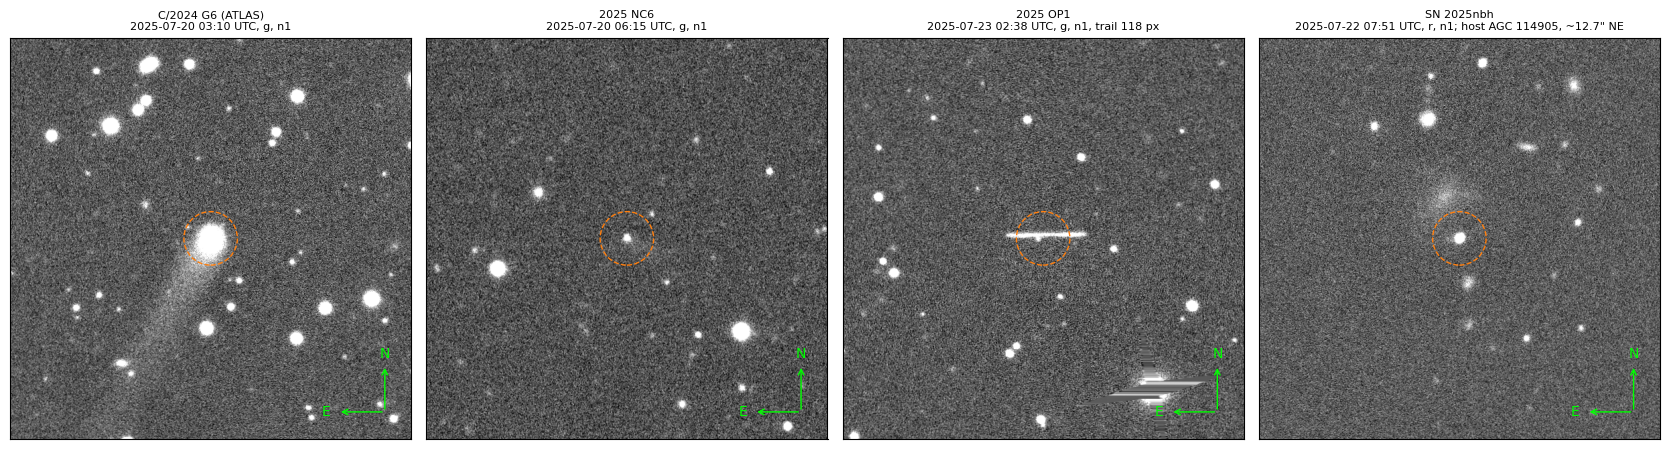

In [8]:
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.visualization import ImageNormalize, ZScaleInterval

panels = []
for name, t in SSO_TARGETS.items():
    row = selected[(selected.ObjID == name) & (selected.visit == t["visit"])].iloc[0]
    trail = f", trail {row.trail_px:.0f} px" if row.trail_px > 5 else ""
    label = f"{row.utc[:16]} UTC, {row.band}, {row.status}{trail}"
    panels.append((name, row.key, row.RA_deg, row.Dec_deg, label))
sn_band = sn.loc[SUPERNOVA["band"]]
sn_label = f"{sn_band.first_utc[:16]} UTC, {SUPERNOVA['band']}, n{int(sn_band.n)}"
sn_label += f"; host {SUPERNOVA['host_note']}"
panels.append((SUPERNOVA["name"], sn_band.key, SUPERNOVA["ra"], SUPERNOVA["dec"], sn_label))

fig, axes = plt.subplots(1, len(panels), figsize=(4.2 * len(panels), 4.8))
for ax, (name, key, ra, dec, label) in zip(axes, panels, strict=True):
    data, wcs = north_up_cutout(key, ra, dec)
    stem = name.replace("/", "_").replace(" ", "_").replace("(", "").replace(")", "")
    header = wcs.to_header()
    header.update(OBJECT=name, BUNIT="nJy", TRACT=key[0], PATCH=key[1], FILTER=key[2])
    fits.PrimaryHDU(data.astype(np.float32), header).writeto(
        WORK / "products" / f"{stem}_{key[2]}.fits", overwrite=True
    )
    ax.imshow(
        data,
        origin="lower",
        cmap="gray",
        norm=ImageNormalize(data[np.isfinite(data)], interval=ZScaleInterval()),
    )
    ax.add_patch(
        plt.Circle(((CUTOUT_PIXELS - 1) / 2,) * 2, 40, fill=False, color="tab:orange", ls="--")
    )
    ax.set_title(f"{name}\n{label}", fontsize=8)
    ax.set_xticks([]), ax.set_yticks([])
    origin = np.array([CUTOUT_PIXELS - 40, 40])  # compass: north up, east left
    for tip, text in ((origin + [0, 70], "N"), (origin - [70, 0], "E")):
        ax.annotate("", xy=tip, xytext=origin, arrowprops=dict(arrowstyle="->", color="lime"))
        ax.text(*(tip + (origin - tip) * -0.25), text, color="lime", ha="center", va="center")
fig.tight_layout()
fig.savefig(WORK / "products" / "edp2_demo_gallery.png", dpi=150)
plt.show()

## Where to go next

* **More objects.** Add names to `SSO_TARGETS` (the reference `visit`/`detector` are only
  used by the acceptance check), or drop the target filter and give Ponder whole MPC
  catalogs, as in the Letter (≈1.5 million MPCORB orbits take hours, not minutes).
* **The rest of the sky.** Every row with status `n1`/`n2` in step 4 is a single-epoch
  image; the full-catalog search, cutout mosaicking across patches, and the trailing
  and depth screens are in
  the Letter's analysis code (Rubin-eDP2-SolSys-Explorer, not yet public).
* **Credit.** Please acknowledge Rubin eDP2 data as described on
  [dp2.lsst.io](https://dp2.lsst.io), and follow Sorcha's citation requirements when
  using Ponder.